# Material de aula - FACENS - Aprendizado de Máquina

Instruções para a realização desta atividade:

1. Faça o download deste notebook Jupyter para sua estação de trabalho
2. Realize as atividades solicitadas dentro do notebook, nos espaços apropriados e indicados
3. Salve o notebook no seguinte padrão: <nome_sobrenome_RA>.ipynb (por exemplo: **rodrigo_caropreso_123456.ipynb ** )
4. Envie o notebook com a atividade realizada na sala de aula da disciplina (Google Classroom)

** DATA DE ENTREGA DESTA ATIVIDADE: 29/12/2018 **

** VALOR DESTA ATIVIDADE: 3,0 pontos **


## RBF- Exercício 01

In [1]:
#CÉLULA RBF-LIB-01
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [2]:
#CÉLULA RBF-LIB-02
def euclidean_distance(v1, v2) :
    '''
    Esta função recebe 2 arrays (do tipo np.array) e retorna a distância euclidiana entre eles
    
    Parâmetros
    ----------
    v1 -> vetor de coordenadas do primeiro ponto
    v2 -> vetor de coordenadas do segundo ponto
    
    Retorno
    -------
    Distância entre os dois pontos    
    '''
    return np.sqrt( sum((v1 - v2)**2) )

In [3]:
#CÉLULA RBF-LIB-05
def kmeans(vData, nClusters) :
    '''
    Este método calcula os centroides dos clusters de um conjunto de dados a partir do algoritmo k-means
    
    Parâmetros
    ----------
    vData -> vetor de coordenadas N-Dimensionais dos dados. Cada posição do array deve ser uma lista de coordenadas
        
    Retorno
    -------
    Array contendo a lista de pontos observados, onde cada posição do array corresponde a um clusterId. 
    Cada ponto do array de retorno é definido como um dicionário com a seguinte estrutura:
        {
         'pointCoord'  : coordenadas do ponto, 
         'centerCoord' : coordenadas de seu centroide, 
         'clusterId'   : identificador do cluster
        }
    '''

    #Inicializa os centroides
    vClusterCenters = [vData[i] for i in range(0, nClusters)]
    
    vPoints = [{'point':point, 'clusterId' : -1, 'centerCoord' : point*0} for point in vData] #tupla (point, clusterCentroid)
    
    clusterIsChanging = True
    while(clusterIsChanging == True) :
    
        clusterIsChanging = False

        vClusterPoints  = [[]] * nClusters #cria lista de listas com tamanho nClusters. O indice primario corresponde a cada cluster

        for dataPoint in vPoints :
            vDistances = [ euclidean_distance(dataPoint['point'], center) for center in vClusterCenters ]
            clusterIndex = np.argmin(vDistances)

            if( dataPoint['clusterId'] != clusterIndex ) :
                dataPoint['clusterId']  = clusterIndex
                clusterIsChanging = True

        #Após a redistribuição dos pontos, recalcula os centroides
        for clusterIndex, clusterCenter in enumerate(vClusterCenters) :
            clusterData = [ point['point'] for point in vPoints if point['clusterId'] == clusterIndex ]
            vClusterCenters[clusterIndex] = np.mean(clusterData, axis=0) #atualiza centroide do cluster indicado pelo clusterIndex

    
    for dataPoint in vPoints :
        dataPoint['centerCoord'] = vClusterCenters[dataPoint['clusterId']]
                    
    return (vPoints, vClusterCenters)

In [4]:
#CÉLULA RBF-LIB-06
def cluster_distortion(vDataPoints, nClusters, bWeighted = False) :
    '''
    Esta função calcula a distorção intra-cluster
    
    Parâmetros
    ----------
    vDataPoints -> array contendo os pontos (dados observados). Cada ponto é definido como um dicionário com a seguinte estrutura
        {'pointCoord' : coordenadas do ponto, 'centerCoord' : coordenadas de seu centroide, 'clusterId' : identificador do cluster}
    
    nClusters   -> quantidade de clusters utilizados
    bWeighted   -> Se for definido como True, cada distorção será ponderada pelo numero de dados do cluster, resultando no 
                   cálculo da distância média quadrática (ou variância da função de ativação da RBF).
    
    Retorno
    -------
    
    Um array contendo a distorção intra-cluster de todos os clusters, onde cada posição do array corresponde ao clusterId    
    '''
    
    vClusterDist = []
    for i in range(nClusters) :
        vClusterPoints = [point for point in vDataPoints if point['clusterId'] == i]
        distance = sum([euclidean_distance(point['point'], point['centerCoord'])**2 for point in vClusterPoints])

        if( bWeighted == True) :
            distance /= len(vClusterPoints)
        
        vClusterDist.append(distance)
    
    return vClusterDist    

In [5]:
#CÉLULA RBF-LIB-08
def avgSquaredError(x, d, W_2) :
    '''
    Calula o Erro Quadratico Medio (ASE)
    
    Parametros
    ----------
    x   -> array de dados da entrada
    d   -> array de dados de saída
    W_2 -> pesos conectando as camadas de entrada e saida
    
    Retorno
    -------
    Valor do EQM para uma época de treinamento.    
    '''
    nSamples = np.shape(x)[1]
    I_2 = np.matmul(W_2, x)
    Y_2 = I_2 #Função de ativação linear
    
    E_k = (d - Y_2)**2
    E_k = np.sum(E_k, axis=0) / 2 #soma os elementos de cada coluna entre si
    ASE = sum(E_k) / nSamples # totaliza os elementos do array fazendo a media
    
    return ASE

In [6]:
#CÉLULA RBF-LIB-09
def rbf_stage1_training(vInputs, nHiddenLayer) :
    '''
    Realiza a fase 1 do treinamento da RBF.
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x    
    '''
    (vPoints, vClusterCenters) = kmeans(vInputs, nHiddenLayer) 

    W_1 = np.array(vClusterCenters) #array de nClusters (linhas) por x entradas (colunas)

    #distorção de cada cluster = campo hiperesferico do neuronio da camada oculta = variancia
    #print(vClusterDist)
    clusterDist = cluster_distortion(vPoints, nHiddenLayer, True)
    sigmaSquared = np.array(clusterDist)

    return (W_1, sigmaSquared)

In [7]:
#CÉLULA RBF-LIB-10
def rbf_stage1_operation(vInputs, c, wVar) :
    '''Algoritmo de operação do RBF - Estagio 1
    
    Parametros
    -----------
    vInputs  : vetor/matriz com as entradas
    c        : vetor/matriz com os pesos
    wVar     : variância dos pesos
    
    Retorno
    -------
    Este método retorna o array de saida [amostras x neuronios] de saída do primeiro estágio da RBF calculado segundo 
    sua função de ativação gaussiana. Cada linha corresponde a uma amostra enquanto cada coluna corresponde a um neurônio da 
    camada oculta
    ''' 

    nSamples = len(vInputs)
    nNeurons = len(c)
    
    #Calcula saída da camada intermediária da RBF
    g = []
    for k in range(nSamples) :
        u = vInputs[k]
        z = (u - c)**2
        num = np.sum(z, axis=1)
        den = 2*sigmaSquared        
        g.append( np.exp( -num / den ) )

    return np.array(g)

In [8]:
#CÉLULA RBF-LIB-11
def rbf_stage2_training(eta, epsilon, vInputs, vOutputs, max_epochs, outLayerSize):
    '''
    Realiza a fase 2 do treinamento da RBF.
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x
    '''
    
    nHiddenNeurons = np.shape(vInputs)[0]    
    nSamples = np.shape(vInputs)[1]
    W_2 = np.random.rand(outLayerSize, nHiddenNeurons)    
   
    vASE = []    
    currentASE = avgSquaredError(vInputs, vOutputs, W_2)
    #Guarda EQM atual
    vASE.append(currentASE)
        
    for epochCounter in range(1, max_epochs) :
        for k in range(nSamples) :
            #Forward Step - INICIO
            X = vInputs[:, [k]]
            d = vOutputs[:, [k]]
            
            I_2 =np.matmul(W_2, X)
            Y_2 = I_2 #função de ativação linear
            #Forward Step - FIM
        
            #Backward Step - INICIO
            delta_2 = d - Y_2 #gradiente da função linear é apenas a diferença entre valores
                        
            #Correção de pesos da camada de saída
            for j in range(outLayerSize) : #cada linha é um neuron de saida
                for i in range(nHiddenNeurons) : #cada coluna é uma sinapse com os neurons da camada oculta
                    W_2[j][i] += eta * delta_2[j] * X[i]
            #Backward Step - FIM
        
        #Fim do loop de amostras (época), calcula o erro
        currentASE = avgSquaredError(vInputs, vOutputs, W_2)
        #Guarda EQM atual
        vASE.append(currentASE)
        
        #Verifica criterio de parada, por convergência
        if( abs(vASE[epochCounter] - vASE[epochCounter-1]) <= epsilon ) :
            break
            
    return (W_2, vASE, epochCounter+1)        

In [9]:
#CÉLULA RBF-LIB-12
def rbf_stage2_operation(X, W_2):
    '''
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x
    
    Espera-se W_2 no formato [ neuronios x sinapses] de modo que cada linha corresponde a um neuronio e cada coluna a uma sinapse
    '''    
    I_2 = np.matmul(W_2, X)
    Y_2 = I_2 #Função de ativação linear

    return Y_2

# Classificação de parâmetros de injeção eletrônica usando RBF

### A quantidade de gasolina {y} a ser injetada por um sistema de injeção eletrônica de combustível para veículos automotores pode ser computada em tempo-real em função de três grandezas {x1 , x2 , x3}. Devido à complexidade inerente do processo, configurado como um sistema não-linear, pretende-se utilizar uma rede neural artificial para o mapeamento entre as entradas e a saída do processo.

### Sabe-se que para efetuar o respectivo mapeamento (problema de aproximação funcional), duas potenciais arquiteturas podem ser aplicadas, a saber, o perceptron multicamadas ou a RBF. Dado que a equipe de engenheiros e cientistas já realizou o mapeamento do problema por meio do perceptron multicamadas, o objetivo agora é treinar uma RBF a fim de que os resultados fornecidos por ambas as arquiteturas possam ser contrastados.

### Assim, efetue o treinamento de uma RBF com o objetivo de computar a quantidade de gasolina {y} a ser injetada pelo sistema de injeção eletrônica em função das variáveis {x1 , x2 , x3}. A topologia da rede RBF está ilustrada na figura abaixo.

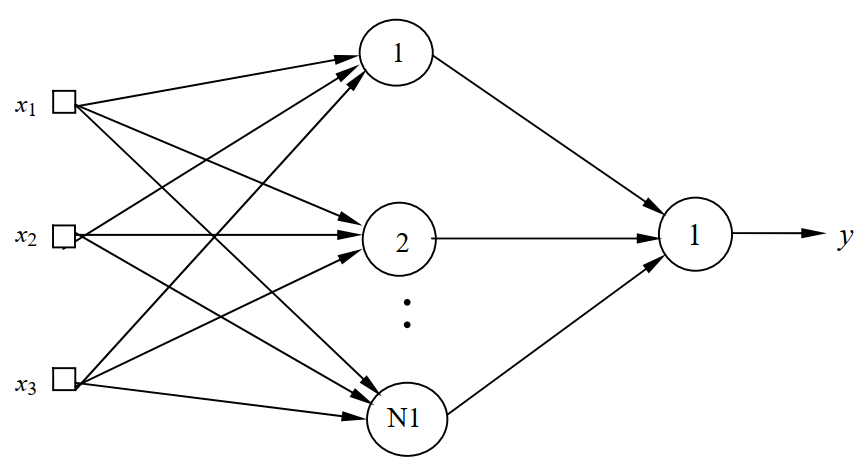


### As topologias candidatas de RBF para serem aplicadas no mapeamento do problema acima são especificadas como se segue:

1. Rede 1: RBF com N1 = 05
2. Rede 2: RBF com N1 = 10
3. Rede 3: RBF com N1 = 15

### Utilizando os dados de treinamento disponíveis no arquivo Injecao.csv, execute o treinamento das redes RBF conforme as topologias definidas acima. Para tanto, faça as seguintes atividades:

## 1 - Execute 3 treinamentos para cada topologia de rede RBF definida anteriormente, inicializando a matriz de pesos da camada de saída com valores aleatórios entre 0 e 1. Se for o caso, reinicie o gerador de números aleatórios em cada treinamento de tal forma que os elementos das matrizes de pesos iniciais não sejam os mesmos. Utilize uma taxa de aprendizado $\eta = 0.01$ e precisão $\epsilon = 10^{-7}$

## 2 - Registre os resultados finais desses 3 treinamentos (o Erro Quadrático Médio e a quantidade de épocas de treinamento), para cada uma das três topologias de rede, na tabela a seguir:


|Treinamento| Rede 1 - EQM | Rede 1 - Epocas | Rede 2 - EQM | Rede 2 - Epocas | Rede 3 - EQM | Rede 3 - Epocas |
|-----------|--------------|-----------------|--------------|-----------------|--------------|-----------------|
|   T1      | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx |
|   T2      | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx |
|   T3      | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx | xxxxxxxxxxxx | xxxxxxxxxxxxxxx |

## 3 - Para todos os treinamentos efetuados no item 2, faça a validação da rede em relação aos valores desejados apresentados na tabela abaixo. Forneça para cada treinamento o erro relativo médio (%) entre os valores desejados e os valores fornecidos pela rede em relação a todos os padrões de teste. Obtenha também a respectiva variância (%)

|Amostra |  X1  |  X2  |  X3  |  yd  |R1:y(T1)|R1:y(T2)|R1:y(T3)|R2:y(T1)|R2:y(T2)|R2:y(T3)|R3:y(T1)|R3:y(T2)|R3:y(T3)|
|--------|------|------|------|------|--------|--------|--------|--------|--------|--------|--------|--------|--------|
|   01   |0.5102|0.7464|0.0860|0.5965|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   02   |0.8401|0.4490|0.2719|0.6790|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   03   |0.1283|0.1882|0.7253|0.4662|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   04   |0.2299|0.1524|0.7353|0.5012|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   05   |0.3209|0.6229|0.5233|0.6810|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   06   |0.8203|0.0682|0.4260|0.5643|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   07   |0.3471|0.8889|0.1564|0.5875|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   08   |0.5762|0.8292|0.4116|0.7853|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   09   |0.9053|0.6245|0.5264|0.8506|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   10   |0.8149|0.0396|0.6227|0.6165|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   11   |0.1016|0.6382|0.3173|0.4957|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   12   |0.9108|0.2139|0.4641|0.6625|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   13   |0.2245|0.0971|0.6136|0.4402|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   14   |0.6423|0.3229|0.8567|0.7663|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   15   |0.5252|0.6529|0.5729|0.7893|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   Erro Relativo Medio (%)  |-|-|-|-|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|
|   Variância (%)            |-|-|-|-|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|xxxxxxxx|


## 4- Para cada uma das topologias apresentadas na tabela acima, considerando ainda o melhor treinamento {T1, T2 ou T3} realizado em cada uma delas, trace o gráfico dos valores de erro quadrático médio (EQM) em função de cada época de treinamento. Plote os três gráficos.

## 5 - Baseado nas análises dos itens acima, indique qual das topologias candidatas {Rede 1, Rede 2 ou Rede 3} e com que qual configuração final de treinamento {T1, T2 ou T3} seria a mais adequada para este problema.

# RBF - Início

In [11]:
#CÉLULA RBF-MAIN-01

#Parâmetros
max_epochs = 10000
eta = 
epsilon = 
layersDescriptor = {'input' : xxx, 'hidden' : xxx, 'output' : 1} #descritor das camadas da RBF

In [12]:
#CÉLULA RBF-MAIN-02
#Carrega dados de treinamento e teste
dfTrainingFile = pd.read_csv('Exe01_Injection_training.csv')

dfOperationFile = pd.read_csv('Exe01_Injection_operation.csv')


D:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
D:\ProgramData\Anaconda3\lib\site-packages\matplotlib\__init__.py:910: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
D:\ProgramData\Anaconda3\lib\site-packages\matplotlib\rcsetup.py:156: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed in 3.0
  mplDeprecation)


Treinamento finalizado em 135 épocas


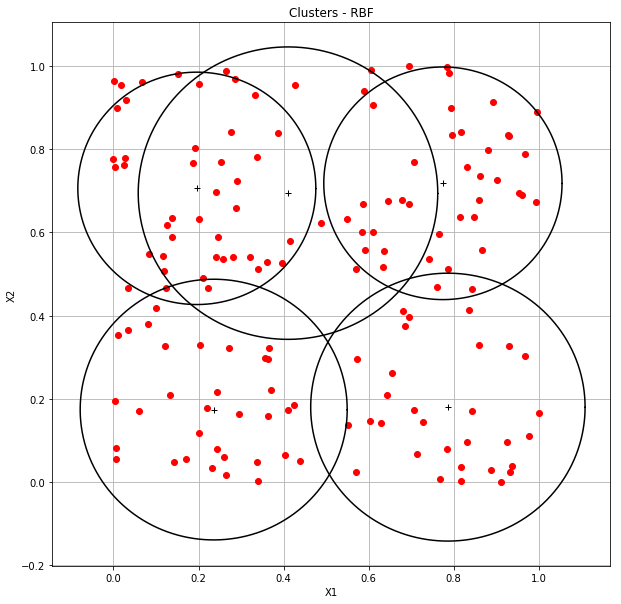

In [13]:
#CÉLULA RBF-MAIN-03
nSamples = len(dfTrainingFile)
vInputs  = np.array(dfTrainingFile.loc[: , 'x1':'x3'])
vOutputs = np.array(dfTrainingFile.loc[: , 'yd'])

#PRIMEIRO ESTAGIO DE TREINAMENTO: Alocação dos neuronios da camada oculta
''' 
{
    'pointCoord'  : coordenadas do ponto, 
    'centerCoord' : coordenadas de seu centroide, 
    'clusterId'   : identificador do cluster
}
'''

#implemente o código para realização do treinamento


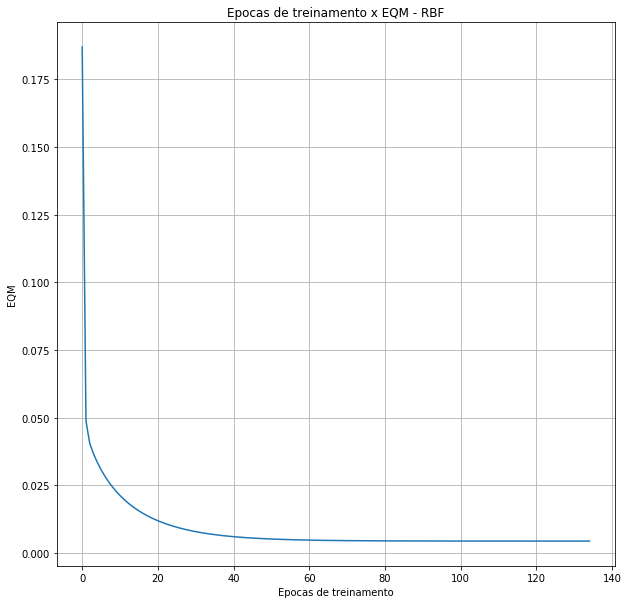

In [14]:
#CÉLULA RBF-MAIN-04
# Plotando o Erro Quadrático Médio
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.xlabel('Epocas de treinamento')
plt.ylabel('EQM')
plt.title('Epocas de treinamento x EQM - RBF')

#implemente o codigo para exibir o grafico do erro quadratico medio em função do numero de epocas


In [15]:
#CÉLULA RBF-MAIN-05
#implemente o código para realização do teste

[[0.60791085 0.73620771 0.43594403 0.44279723 0.70268141 0.59635277
  0.54344563 0.82870079 0.82448853 0.59490503 0.46387604 0.65060284
  0.37123677 0.71501604 0.88315853]]
------------
[0.5965 0.679  0.4662 0.5012 0.681  0.5643 0.5875 0.7853 0.8506 0.6165
 0.4957 0.6625 0.4402 0.7663 0.7893]


## Implemente a expressão que calcula o Erro Relativo médio e a variância, para inserir os dados na tabela acima

$$ MRE = \frac{|valor\_aprox - valor\_exato |}{valor\_exato} \times 100 \% $$

### Lembre-se que a expressão acima calcula somente o erro relativo para UM PAR (Y_previsto, Y_esperado). O Erro relativo médio será a MÉDIA dos Erros Relativos para todos os pares (Y_previsto, Y_esperado) do conjunto de testes.

In [16]:
#Erro Relativo Médio
